# Detecção de anomalias em transações
## Contexto e método
Comparação de modelos para identificar transações anômalas. Dados consultados em22/11/2026.
Dados públicos anonimizados: https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv .
Sem dados de clientes, credenciais ou uso em produção.

**Pergunta:** como detectar fraudes raras sem confundir alta acurácia com utilidade?
Compararemos regressão logística, Random Forest e XGBoost, com recall, precisão, F1 e curvas ROC/PR.

### Hipóteses e limites
Uma linha é uma transação. Class=1 indica fraude. V1–V28 são componentes PCA sem significado comercial recuperável.
Duplicatas exatas são removidas antes da divisão para evitar vazamento entre conjuntos.
Treino/validação/teste estratificados de 60/20/20; transformações são ajustadas somente no treino.
Modelo e limiar são escolhidos **na validação** por recall e, no empate, precisão. O teste não participa dessa escolha.
Divisão aleatória não demonstra desempenho em períodos futuros; custos, deriva e calibração exigiriam validação adicional.

## Resultado observado
Na validação, a regra de maior recall escolheu **Logistica com limiar 0.3**. No teste reservado, identificou **83 de 95 fraudes** (recall 87.37%), mas gerou **3187 falsos positivos** (precisão 2.54%, F1 0.0493). Isso demonstra por que maximizar recall isoladamente pode ser impraticável. O limiar 0,3 não elevou recall no teste em relação a 0,5 e aumentou falsos alarmes; não alteramos a escolha após observar o teste. Não é uma recomendação operacional. As comparações completas, curvas e SHAP estão salvas abaixo.


In [1]:
import json, hashlib, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, classification_report, confusion_matrix,
    RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import shap
SEED = 42
OUTPUT = Path("resultados")
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print("Ambiente:", sys.version.split()[0])

<ambiente-local>/Lib/site-packages/tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Ambiente: 3.14.3


## Dados
O link é a origem da leitura. Cache local em `data/` evita downloads repetidos; CSV não é incluído no repositório.
Validações: esquema, ausência de nulos, valores de classe, Amount não negativo e duplicatas.
A prévia é inspecionada em memória; as saídas públicas apresentam somente contagens e metadados agregados.

In [2]:
URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
CACHE = Path("data/creditcard.csv")
if CACHE.exists():
    raw = pd.read_csv(CACHE)
else:
    raw = pd.read_csv(URL)
    CACHE.parent.mkdir(exist_ok=True)
    raw.to_csv(CACHE, index=False)
preview = raw.head()
expected = {"Time", "Amount", "Class", *[f"V{i}" for i in range(1,29)]}
assert set(raw.columns) == expected
assert raw.notna().all().all()
assert set(raw.Class.unique()) == {0,1}
assert (raw.Amount >= 0).all()
duplicates = int(raw.duplicated().sum())
data = raw.drop_duplicates().reset_index(drop=True)
source = {"url": URL, "raw_rows": len(raw), "rows_after_deduplication": len(data),
          "duplicates_removed": duplicates, "raw_frauds": int(raw.Class.sum()),
          "raw_fraud_fraction": float(raw.Class.mean()),
          "sha256_cache": hashlib.sha256(CACHE.read_bytes()).hexdigest()}
print(json.dumps(source, indent=2))
display(pd.DataFrame({"quantidade":data.Class.value_counts(),"proporcao":data.Class.value_counts(normalize=True)}).rename_axis("classe"))

{
  "url": "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv",
  "raw_rows": 284807,
  "rows_after_deduplication": 283726,
  "duplicates_removed": 1081,
  "raw_frauds": 492,
  "raw_fraud_fraction": 0.001727485630620034,
  "sha256_cache": "76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89"
}


,quantidade,proporcao
classe,,
0,283253,0.998333
1,473,0.001667


## Preparação e comparação na validação
`log1p(Amount)` reduz assimetria. O scaler está dentro do Pipeline inclusive na busca cruzada.
Pesos equilibram o custo das classes sem criar observações artificiais; oversampling é extensão opcional.
Não fazemos reamostragem antes de separar os conjuntos. Busca pequena e explícita em C da regressão logística,
com três folds estratificados e scoring recall; Random Forest e XGBoost usam configuração fixa documentada.

In [3]:
X = data.drop(columns="Class")
y = data.Class
X_dev, X_test, y_dev, y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_dev,y_dev,test_size=0.25,stratify=y_dev,random_state=SEED)
assert not (set(X_train.index)&set(X_valid.index) or set(X_train.index)&set(X_test.index) or set(X_valid.index)&set(X_test.index))
display(pd.DataFrame([{ "conjunto":name,"n":len(v),"fraudes":int(v.sum()),"proporcao":float(v.mean())}
                      for name,v in [("treino",y_train),("validacao",y_valid),("teste",y_test)]]))
def log_amount(frame):
    return frame.assign(LogAmount=np.log1p(frame.Amount)).drop(columns="Amount")
def pipeline(estimator):
    return Pipeline([("log_amount",FunctionTransformer(log_amount,validate=False)),("scaler",StandardScaler()),("model",estimator)])
ratio = float((y_train==0).sum()/(y_train==1).sum())
grid = GridSearchCV(pipeline(LogisticRegression(class_weight="balanced",max_iter=2000,random_state=SEED)),
                    {"model__C":[0.1,1.0]},scoring="recall",cv=StratifiedKFold(3,shuffle=True,random_state=SEED),n_jobs=2)
grid.fit(X_train,y_train)
models = {"Logistica": grid.best_estimator_,
          "RandomForest": pipeline(RandomForestClassifier(n_estimators=120,max_depth=12,min_samples_leaf=2,class_weight="balanced",n_jobs=2,random_state=SEED)),
          "XGBoost": pipeline(XGBClassifier(n_estimators=180,max_depth=4,learning_rate=0.08,subsample=0.9,colsample_bytree=0.9,
                                          scale_pos_weight=ratio,eval_metric="logloss",tree_method="hist",n_jobs=2,random_state=SEED))}
print("GridSearchCV (recall):",grid.best_params_,"score medio",grid.best_score_)
for name,model in models.items():
    if name != "Logistica": model.fit(X_train,y_train)
    print("Treinado:",name,flush=True)
def metrics(name,truth,probability,threshold):
    pred = (probability>=threshold).astype(int)
    return {"modelo":name,"limiar":threshold,"recall":float(recall_score(truth,pred)),
            "precisao":float(precision_score(truth,pred,zero_division=0)),"f1":float(f1_score(truth,pred)),
            "acuracia":float(accuracy_score(truth,pred)),"average_precision":float(average_precision_score(truth,probability)),
            "roc_auc":float(roc_auc_score(truth,probability))}
validation = pd.DataFrame([metrics(name,y_valid,model.predict_proba(X_valid)[:,1],t)
                           for name,model in models.items() for t in [0.5,0.3]])
display(validation.round(5))
choice = validation.sort_values(["recall","precisao","average_precision","modelo","limiar"],ascending=[False,False,False,True,True]).iloc[0]
selected_name, threshold = str(choice.modelo), float(choice.limiar)
selected_model = models[selected_name]
print("Selecao fixada ANTES de avaliar teste:",selected_name,"limiar",threshold)

,conjunto,n,fraudes,proporcao
0,treino,170235,284,0.001668
1,validacao,56745,94,0.001657
2,teste,56746,95,0.001674


GridSearchCV (recall): {'model__C': 0.1} score medio 0.8904441955953714
Treinado: Logistica


Treinado: RandomForest


Treinado: XGBoost


,modelo,limiar,recall,precisao,f1,acuracia,average_precision,roc_auc
0,Logistica,0.5,0.90426,0.05329,0.10065,0.97323,0.78975,0.98011
1,Logistica,0.3,0.91489,0.02653,0.05156,0.94424,0.78975,0.98011
2,RandomForest,0.5,0.85106,0.82474,0.83770,0.99945,0.85959,0.96726
3,RandomForest,0.3,0.88298,0.65354,0.75113,0.99903,0.85959,0.96726
4,XGBoost,0.5,0.87234,0.71304,0.78469,0.99921,0.87490,0.97392
5,XGBoost,0.3,0.88298,0.52201,0.65613,0.99847,0.87490,0.97392


Selecao fixada ANTES de avaliar teste: Logistica limiar 0.3


## Resultados no teste reservado
Agora a escolha está congelada. Mostramos todas as alternativas para auditoria, sem selecionar novamente no teste.
O baseline que nunca marca fraude pode ter alta acurácia e recall zero.
Average precision resume a curva PR; não confundir com a precisão em um único limiar.

In [4]:
test_probabilities = {name:model.predict_proba(X_test)[:,1] for name,model in models.items()}
test_results = pd.DataFrame([metrics(name,y_test,p,t) for name,p in test_probabilities.items() for t in [0.5,0.3]])
display(test_results.round(5))
prob = test_probabilities[selected_name]
pred = (prob>=threshold).astype(int)
selected_metrics = metrics(selected_name,y_test,prob,threshold)
baseline = {"acuracia":float((y_test==0).mean()),"recall":0.0,"fraudes_detectadas":0}
print("Baseline sempre normal:",baseline)
print(classification_report(y_test,pred,digits=4,zero_division=0))
cm = confusion_matrix(y_test,pred,labels=[0,1])
assert cm.sum()==len(y_test)
assert np.isclose(selected_metrics["recall"],cm[1,1]/cm[1].sum())
assert np.isclose(selected_metrics["precisao"],cm[1,1]/max(1,cm[:,1].sum()))
report = {"source":source,"splits":{k:len(v) for k,v in [("train",y_train),("validation",y_valid),("test",y_test)]},
          "selection":"validation recall, precision tie-break; thresholds 0.5 and 0.3",
          "grid_best_params":grid.best_params_,"grid_recall":float(grid.best_score_),
          "validation":validation.to_dict(orient="records"),"test":test_results.to_dict(orient="records"),
          "selected":selected_metrics,"confusion_matrix":cm.tolist(),"baseline":baseline}
(OUTPUT/"metricas.json").write_text(json.dumps(report,indent=2),encoding="utf-8")

,modelo,limiar,recall,precisao,f1,acuracia,average_precision,roc_auc
0,Logistica,0.5,0.87368,0.04994,0.09448,0.97196,0.67649,0.96173
1,Logistica,0.3,0.87368,0.02538,0.04933,0.94363,0.67649,0.96173
2,RandomForest,0.5,0.76842,0.84884,0.80663,0.99938,0.79321,0.95187
3,RandomForest,0.3,0.80000,0.66667,0.72727,0.99900,0.79321,0.95187
4,XGBoost,0.5,0.80000,0.67857,0.73430,0.99903,0.80381,0.96965
5,XGBoost,0.3,0.83158,0.51974,0.63968,0.99843,0.80381,0.96965


Baseline sempre normal: {'acuracia': 0.9983258731892997, 'recall': 0.0, 'fraudes_detectadas': 0}
              precision    recall  f1-score   support

           0     0.9998    0.9437    0.9710     56651
           1     0.0254    0.8737    0.0493        95

    accuracy                         0.9436     56746
   macro avg     0.5126    0.9087    0.5101     56746
weighted avg     0.9981    0.9436    0.9694     56746



4593

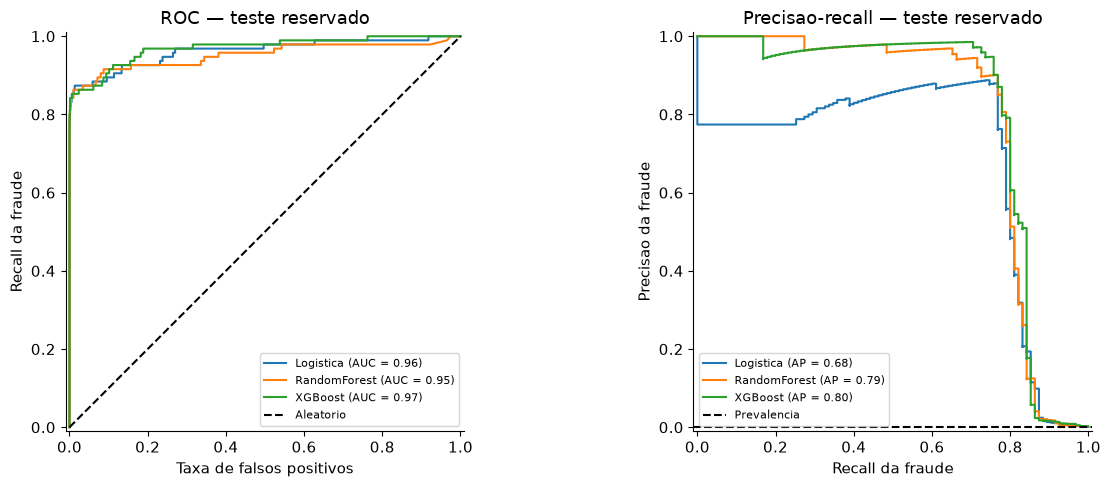

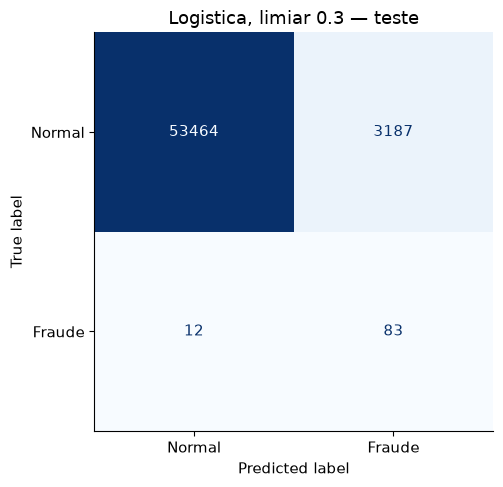

In [5]:
fig,axes = plt.subplots(1,2,figsize=(13,5))
for name,p in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test,p,name=name,ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test,p,name=name,ax=axes[1])
axes[0].plot([0,1],[0,1],"k--",label="Aleatorio")
axes[1].axhline(float(y_test.mean()),color="black",linestyle="--",label="Prevalencia")
axes[0].set(title="ROC — teste reservado",xlabel="Taxa de falsos positivos",ylabel="Recall da fraude")
axes[1].set(title="Precisao-recall — teste reservado",xlabel="Recall da fraude",ylabel="Precisao da fraude")
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUTPUT/"curvas.png",dpi=140,bbox_inches="tight");fig.savefig(OUTPUT/"curvas.svg",bbox_inches="tight");plt.show()
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(cm,display_labels=["Normal","Fraude"]).plot(ax=ax,colorbar=False,cmap="Blues")
ax.set_title(f"{selected_name}, limiar {threshold} — teste")
fig.tight_layout();fig.savefig(OUTPUT/"matriz.png",dpi=140,bbox_inches="tight");fig.savefig(OUTPUT/"matriz.svg",bbox_inches="tight");plt.show()

## Explicabilidade
Importância por redução de impureza do Random Forest é descritiva e pode ter vieses.
SHAP é aplicado ao **modelo escolhido**, nas entradas transformadas pelo seu Pipeline.
O gráfico local usa a transação com maior escore no teste, escolhida pelo escore e não pelo rótulo.
Valores SHAP explicam a saída do modelo; não demonstram causa real da fraude. Para regressão logística, a escala é log-odds.

,importancia_random_forest
V14,0.183200
V10,0.133176
V4,0.113240
V12,0.106254
V17,0.090490
V3,0.061929
V11,0.041445
V16,0.040118
V2,0.033462
V9,0.023218


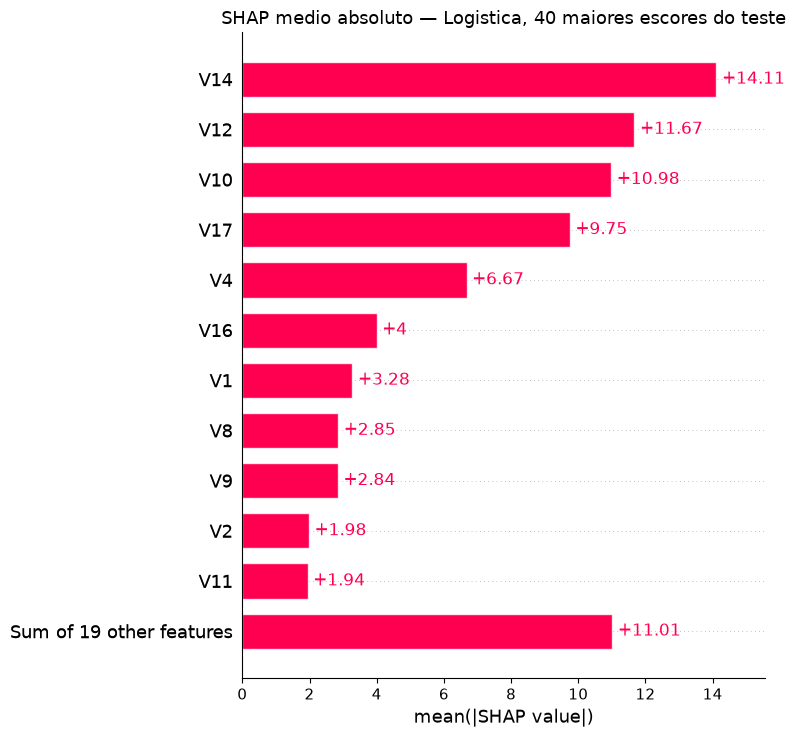

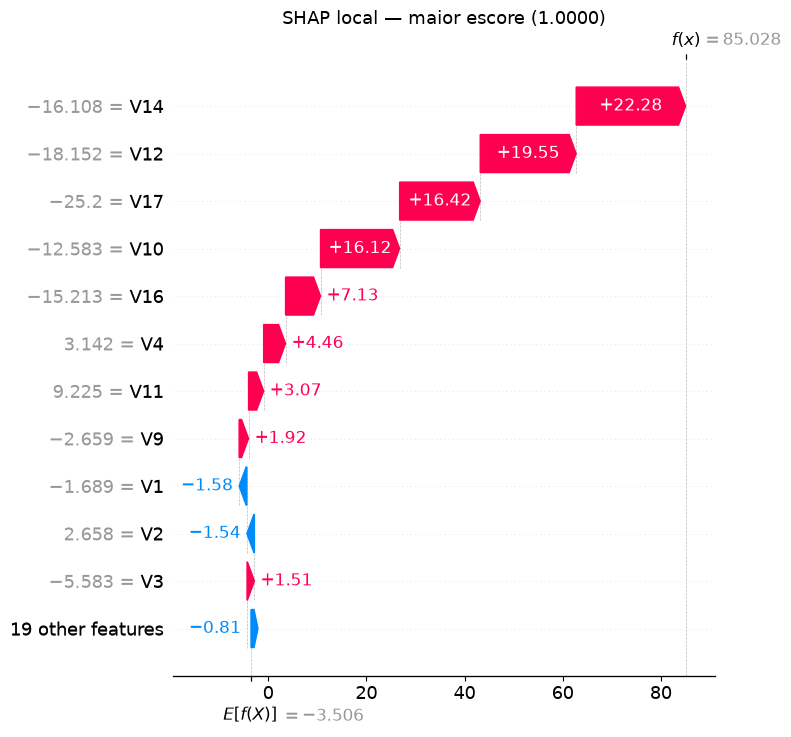

,SHAP_medio_absoluto
V14,14.112148
V12,11.670732
V10,10.980537
V17,9.748368
V4,6.673240
V16,3.996045
V1,3.276143
V8,2.853813
V9,2.843866
V2,1.984238


5101

In [6]:
feature_names = list(log_amount(X_train).columns)
importance = pd.Series(models["RandomForest"].named_steps["model"].feature_importances_,index=feature_names).sort_values(ascending=False).head(10)
display(importance.rename("importancia_random_forest").to_frame())
background = selected_model[:-1].transform(X_train.sample(60,random_state=SEED))
order = np.argsort(prob)[::-1][:40]
explain_X = selected_model[:-1].transform(X_test.iloc[order])
estimator = selected_model.named_steps["model"]
explainer = shap.Explainer(estimator,background,feature_names=feature_names)
explanation = explainer(explain_X)
if explanation.values.ndim==3: explanation=explanation[:,:,1]
assert np.isfinite(explanation.values).all()
shap.plots.bar(explanation,max_display=12,show=False)
plt.title(f"SHAP medio absoluto — {selected_name}, 40 maiores escores do teste")
plt.tight_layout();plt.savefig(OUTPUT/"shap-global.png",dpi=140,bbox_inches="tight");plt.savefig(OUTPUT/"shap-global.svg",bbox_inches="tight");plt.show()
shap.plots.waterfall(explanation[0],max_display=12,show=False)
plt.title(f"SHAP local — maior escore ({prob[order[0]]:.4f})")
plt.tight_layout();plt.savefig(OUTPUT/"shap-local.png",dpi=140,bbox_inches="tight");plt.savefig(OUTPUT/"shap-local.svg",bbox_inches="tight");plt.show()
shap_ranking = pd.Series(np.abs(explanation.values).mean(axis=0),index=feature_names).sort_values(ascending=False)
display(shap_ranking.head(10).rename("SHAP_medio_absoluto").to_frame())
report["shap"]={"model":selected_name,"rows":len(order),"scope":"40 highest test scores; not representative of all transactions",
                "top_features":shap_ranking.head(10).to_dict(),"local_score":float(prob[order[0]])}
(OUTPUT/"metricas.json").write_text(json.dumps(report,indent=2),encoding="utf-8")

## Conclusões e limites
A tabela de teste e a matriz mostram o compromisso entre fraudes detectadas e falsos alarmes.
Diminuir o limiar não cria qualidade gratuitamente: pode elevar recall e reduzir precisão.
Os resultados dependem do split e de poucas fraudes; não foram validados prospectivamente nem com custos operacionais reais.
O SHAP global mostrado descreve apenas 40 maiores escores, não toda a população.
Diferenças próprias: deduplicação, três conjuntos separados, transformações dentro do CV,
seleção sem consultar teste, baseline explícito e verificações aritméticas da matriz.
Não há autorização técnica para uso financeiro real a partir deste experimento.